# Análise exploratória dos dados - dataset tiny

Inteligência Artificial 2026/27, Grupo G21

Objetivos:

1. carregar os CSV e explorar os dados;
2. validar a integridade dos dados e das janelas de tempo;
3. comparar os pesos com a capacidade dos veículos;
4. mapear as paragens.

Para analisar outro dataset basta mudar a variável `DATASET` (por exemplo para `"small"`).

## 1. Carregar os CSV

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
sys.path.insert(0, str(RAIZ / "src"))

import pandas as pd
import matplotlib.pyplot as plt

DATASET = "tiny"
PASTA = RAIZ / f"data_{DATASET}"

tabelas = {f.stem: pd.read_csv(f) for f in sorted(PASTA.glob("*.csv"))}
for nome, t in tabelas.items():
    print(f"{nome:<20} {len(t):>4} linhas  {len(t.columns):>2} colunas")

collection_centers      1 linhas   5 colunas
customers              12 linhas   5 colunas
delivery_locations      5 linhas   5 colunas
distance_matrix        72 linhas   6 colunas
localities             49 linhas   6 colunas
locations               9 linhas   7 colunas
order_items            40 linhas   9 colunas
orders                 12 linhas   5 colunas
producers               3 linhas   6 colunas
products               15 linhas   6 colunas
rules                  10 linhas   3 colunas
vehicles                2 linhas   6 colunas


In [2]:
items = tabelas["order_items"].copy()
for c in ["availability_start", "availability_end", "delivery_start", "delivery_end"]:
    items[c] = pd.to_datetime(items[c])

orders, products = tabelas["orders"], tabelas["products"]
vehicles, locations = tabelas["vehicles"], tabelas["locations"]
dm = tabelas["distance_matrix"]
regras = tabelas["rules"].set_index("rule")["value"]

items = (items.merge(products[["product_id", "producer_id"]], on="product_id")
              .merge(orders[["order_id", "delivery_location_id"]], on="order_id"))
items.head()

,order_item_id,order_id,product_id,quantity,weight_kg,availability_start,availability_end,delivery_start,delivery_end,producer_id,delivery_location_id
0,1,1,10,6.3,6.3,2026-10-31 07:30:00,2026-10-31 10:30:00,2026-10-31 10:30:00,2026-10-31 12:45:00,2,3
1,2,1,3,3.7,3.7,2026-10-31 08:15:00,2026-10-31 11:15:00,2026-10-31 10:30:00,2026-10-31 12:45:00,1,3
2,3,1,15,4.9,4.9,2026-10-31 07:30:00,2026-10-31 10:15:00,2026-10-31 10:30:00,2026-10-31 12:45:00,3,3
3,4,1,13,7.1,7.1,2026-10-31 07:15:00,2026-10-31 10:45:00,2026-10-31 10:30:00,2026-10-31 12:45:00,3,3
4,5,2,3,1.8,1.8,2026-10-30 07:15:00,2026-10-30 11:15:00,2026-10-31 07:15:00,2026-10-31 10:15:00,1,4


Regras do problema (`rules.csv`):

In [3]:
tabelas["rules"]

,rule,value,description
0,start_date,2026-10-30,first day of the planning horizon
1,horizon_days,2,number of days
2,flow,producer>warehouse>delivery_location,every product goes through the warehouse
3,stop_service_min,10,service time at each pickup / delivery stop
4,warehouse_handling_min,15,time to unload (and to load) a vehicle at the ...
5,max_warehouse_dwell_h,24,max time a product stays in the warehouse (arr...
6,window_semantics,service_start,windows constrain when the service STARTS
7,avg_speed_kmh,45.0,used to build duration_min
8,route_factor,1.3,used to build distance_km
9,generator_seed,1,seed that produced this dataset


## 2. Integridade dos dados

### 2.1 Valores em falta e linhas duplicadas

In [4]:
pd.DataFrame({nome: {"valores em falta": int(t.isna().sum().sum()),
                     "linhas duplicadas": int(t.duplicated().sum())}
              for nome, t in tabelas.items()}).T

,valores em falta,linhas duplicadas
collection_centers,0,0
customers,0,0
delivery_locations,0,0
distance_matrix,0,0
localities,0,0
locations,0,0
order_items,0,0
orders,0,0
producers,0,0
products,0,0


### 2.2 Referências entre tabelas

Cada id usado numa tabela tem de existir na tabela de origem.

In [5]:
relacoes = [
    ("products", "producer_id", "producers", "producer_id"),
    ("order_items", "product_id", "products", "product_id"),
    ("order_items", "order_id", "orders", "order_id"),
    ("orders", "customer_id", "customers", "customer_id"),
    ("orders", "delivery_location_id", "delivery_locations", "delivery_location_id"),
    ("vehicles", "center_id", "collection_centers", "center_id"),
]
for t1, c1, t2, c2 in relacoes:
    em_falta = set(tabelas[t1][c1]) - set(tabelas[t2][c2])
    print(f"{t1}.{c1:<22} -> {t2:<20} {'OK' if not em_falta else 'faltam ' + str(em_falta)}")

products.producer_id            -> producers            OK
order_items.product_id             -> products             OK
order_items.order_id               -> orders               OK
orders.customer_id            -> customers            OK
orders.delivery_location_id   -> delivery_locations   OK
vehicles.center_id              -> collection_centers   OK


### 2.3 Matriz de distâncias

A matriz tem de ter todos os pares de locais, não pode ter valores negativos e deve ser igual nos dois sentidos.

In [6]:
ids = set(locations["location_id"])
km = {(a, b): d for a, b, d in zip(dm.origin_location_id, dm.destination_location_id, dm.distance_km)}
pares = {(a, b) for a in ids for b in ids if a != b}
velocidade = (dm.distance_km / (dm.duration_min / 60)).dropna()

print("Pares esperados:", len(pares))
print("Pares na matriz:", len(km))
print("Pares em falta:", len(pares - set(km)))
print("Distâncias negativas:", int((dm.distance_km < 0).sum()))
print("Simétrica:", all(abs(km[a, b] - km[b, a]) < 1e-6 for a, b in km))
print(f"Velocidade média: {velocidade.mean():.1f} km/h")

Pares esperados: 72
Pares na matriz: 72
Pares em falta: 0
Distâncias negativas: 0
Simétrica: True
Velocidade média: 45.0 km/h


## 3. Janelas de tempo

Cada item tem uma janela de recolha (no produtor) e uma janela de entrega (no cliente).

In [7]:
inicio = pd.Timestamp(regras["start_date"])
fim = inicio + pd.Timedelta(days=int(regras["horizon_days"]))

verificacoes = {
    "recolha: início antes do fim": (items.availability_start < items.availability_end).all(),
    "entrega: início antes do fim": (items.delivery_start < items.delivery_end).all(),
    "recolha começa antes do fim da entrega": (items.availability_start < items.delivery_end).all(),
    "janelas dentro do horizonte": ((items.availability_start >= inicio) & (items.delivery_end <= fim)).all(),
}
for texto, ok in verificacoes.items():
    print(f"{'OK  ' if ok else 'ERRO'} {texto}")

duracao = pd.DataFrame({
    "janela de recolha (h)": (items.availability_end - items.availability_start).dt.total_seconds() / 3600,
    "janela de entrega (h)": (items.delivery_end - items.delivery_start).dt.total_seconds() / 3600,
})
duracao.describe().loc[["min", "mean", "max"]].round(2)

OK   recolha: início antes do fim
OK   entrega: início antes do fim
OK   recolha começa antes do fim da entrega
OK   janelas dentro do horizonte


,janela de recolha (h),janela de entrega (h)
min,1.75,1.50
mean,2.84,2.49
max,4.00,3.75


### 3.1 Tempo mínimo no armazém

Tempo entre o fim da janela de recolha e o início da janela de entrega. Se fosse maior do que 24 h, o item não poderia ser servido.

In [8]:
espera = ((items.delivery_start - items.availability_end).dt.total_seconds() / 3600).clip(lower=0)
max_h = float(regras["max_warehouse_dwell_h"])
dia_seguinte = (items.availability_start.dt.date != items.delivery_start.dt.date).sum()

print(f"Espera mínima no armazém: entre {espera.min():.1f} h e {espera.max():.1f} h")
print(f"Itens com espera mínima acima de {max_h:.0f} h: {int((espera > max_h).sum())}")
print(f"Itens recolhidos num dia e entregues no seguinte: {int(dia_seguinte)}")

Espera mínima no armazém: entre 0.0 h e 23.8 h
Itens com espera mínima acima de 24 h: 0
Itens recolhidos num dia e entregues no seguinte: 10


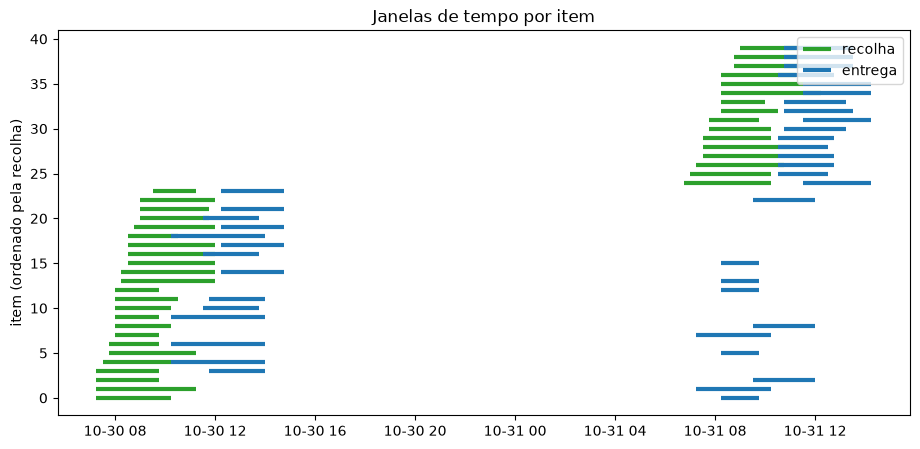

In [9]:
ordem = items.sort_values("availability_start").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(11, 5))
ax.hlines(ordem.index, ordem.availability_start, ordem.availability_end, color="tab:green", lw=3, label="recolha")
ax.hlines(ordem.index, ordem.delivery_start, ordem.delivery_end, color="tab:blue", lw=3, label="entrega")
ax.set_title("Janelas de tempo por item")
ax.set_ylabel("item (ordenado pela recolha)")
ax.legend()
plt.show()

### 3.2 Encomendas

Os itens de uma encomenda vão todos para o mesmo local de entrega, mas podem vir de produtores diferentes.

In [10]:
por_encomenda = items.groupby("order_id").agg(
    itens=("order_item_id", "count"),
    produtores=("producer_id", "nunique"),
    peso_kg=("weight_kg", "sum"),
    entrega_abre=("delivery_start", "max"),
    entrega_fecha=("delivery_end", "min"),
)
por_encomenda["janela comum"] = por_encomenda.entrega_abre < por_encomenda.entrega_fecha
por_encomenda

,itens,produtores,peso_kg,entrega_abre,entrega_fecha,janela comum
order_id,,,,,,
1,4,3,22.0,2026-10-31 10:30:00,2026-10-31 12:45:00,True
2,2,2,6.8,2026-10-31 07:15:00,2026-10-31 10:15:00,True
3,4,3,21.6,2026-10-31 11:30:00,2026-10-31 14:15:00,True
4,3,3,26.3,2026-10-30 11:30:00,2026-10-30 13:45:00,True
5,2,2,9.3,2026-10-31 10:30:00,2026-10-31 12:30:00,True
6,2,2,16.7,2026-10-31 10:45:00,2026-10-31 13:15:00,True
7,4,2,33.5,2026-10-31 10:45:00,2026-10-31 13:30:00,True
8,3,2,18.8,2026-10-31 09:30:00,2026-10-31 12:00:00,True
9,5,3,36.7,2026-10-31 08:15:00,2026-10-31 09:45:00,True


## 4. Pesos e capacidades

In [11]:
cap = vehicles.set_index("vehicle_id")["capacity_kg"]
peso_dia = items.groupby(items.availability_start.dt.date)["weight_kg"].sum()

print(f"Peso total a transportar: {items.weight_kg.sum():.1f} kg")
print(f"Capacidade da frota: {cap.sum():.0f} kg ({', '.join(f'{c:.0f}' for c in cap)})")
print(f"Encomenda mais pesada: {por_encomenda.peso_kg.max():.1f} kg")
print(f"Encomendas que não cabem no maior veículo: {int((por_encomenda.peso_kg > cap.max()).sum())}")
print()
print("Peso a recolher por dia (kg):")
print(peso_dia.round(1).to_string())

Peso total a transportar: 270.0 kg
Capacidade da frota: 350 kg (150, 200)
Encomenda mais pesada: 51.1 kg
Encomendas que não cabem no maior veículo: 0

Peso a recolher por dia (kg):
availability_start
2026-10-30    166.9
2026-10-31    103.1


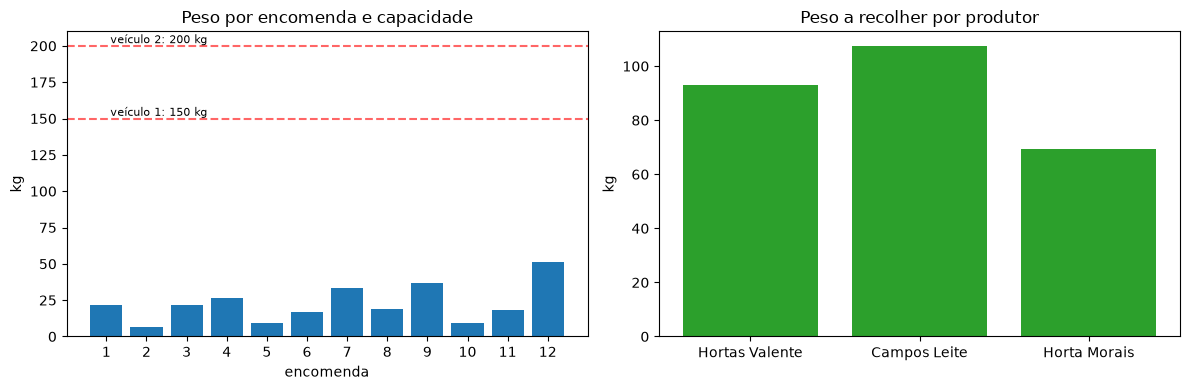

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(por_encomenda.index.astype(str), por_encomenda.peso_kg)
for v, c in cap.items():
    ax[0].axhline(c, ls="--", color="red", alpha=0.6)
    ax[0].text(0, c, f" veículo {v}: {c:.0f} kg", va="bottom", fontsize=8)
ax[0].set_title("Peso por encomenda e capacidade")
ax[0].set_xlabel("encomenda")
ax[0].set_ylabel("kg")

nomes = tabelas["producers"].set_index("producer_id")["name"]
peso_prod = items.groupby("producer_id")["weight_kg"].sum()
ax[1].bar([nomes[p] for p in peso_prod.index], peso_prod.values, color="tab:green")
ax[1].set_title("Peso a recolher por produtor")
ax[1].set_ylabel("kg")
plt.tight_layout()
plt.show()

## 5. Mapa das paragens

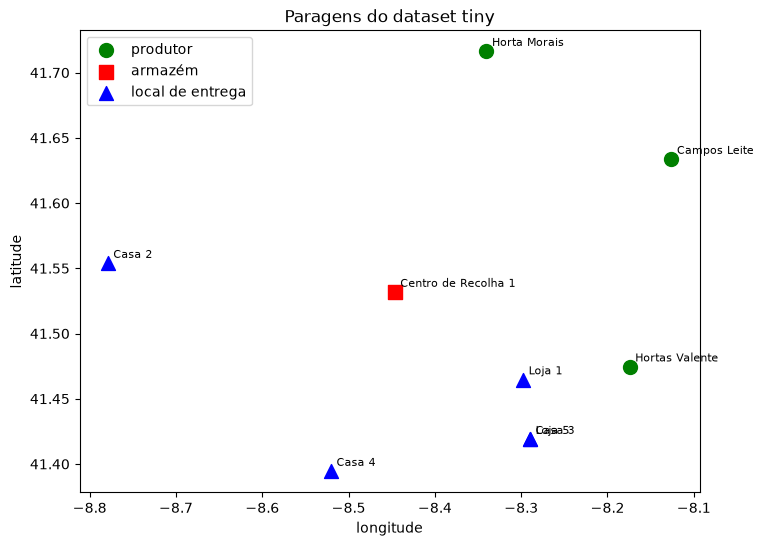

In [13]:
estilos = {"producer": ("green", "o", "produtor"),
           "collection_center": ("red", "s", "armazém"),
           "delivery_location": ("blue", "^", "local de entrega")}
fig, ax = plt.subplots(figsize=(8, 6))
for tipo, (cor, marca, nome) in estilos.items():
    g = locations[locations.location_type == tipo]
    ax.scatter(g.longitude, g.latitude, c=cor, marker=marca, s=100, label=nome)
    for _, r in g.iterrows():
        ax.annotate(r["name"], (r.longitude, r.latitude), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
ax.set_title(f"Paragens do dataset {DATASET}")
ax.legend()
plt.show()

In [14]:
armazem = int(locations.loc[locations.location_type == "collection_center", "location_id"].iloc[0])
dist = pd.DataFrame({"paragem": locations.name, "tipo": locations.location_type,
                     "km ao armazém": [km.get((armazem, i), 0.0) for i in locations.location_id]})
dist[dist.tipo != "collection_center"].sort_values("km ao armazém")

,paragem,tipo,km ao armazém
4,Loja 1,delivery_location,18.79
7,Casa 4,delivery_location,21.39
6,Casa 3,delivery_location,23.53
8,Loja 5,delivery_location,23.53
2,Horta Morais,producer,29.06
0,Hortas Valente,producer,30.60
5,Casa 2,delivery_location,36.12
1,Campos Leite,producer,37.66


## 6. Conclusões

- O dataset tiny tem 3 produtores, 5 locais de entrega, 12 encomendas (40 itens, 270 kg) e 2 veículos com 150 kg e 200 kg. Não há valores em falta, duplicados nem referências inválidas.
- A matriz de distâncias está completa e é simétrica, e os tempos correspondem a 45 km/h. Há locais com distância 0 entre si porque têm as mesmas coordenadas.
- As janelas de tempo são válidas e estão dentro do horizonte de 2 dias. Alguns itens são recolhidos num dia e entregues no seguinte, ficando a noite no armazém, mas sempre menos de 24 h.
- Nenhuma encomenda passa a capacidade de um veículo e a frota (350 kg) aguenta o peso total. O que vai limitar as rotas são as janelas de tempo e não a capacidade.
- Os produtores ficam a nordeste e a leste do armazém e os clientes a sul e a oeste, por isso as rotas acabam sempre por passar pelo armazém a meio.